# 04 – Points of interest (function)

**Goal:** describe what a place is *used for* (eating, shopping, school, doctor, public services, culture/sport/tourism) from OpenStreetMap points of interest (POI).
This replaces Urban Atlas: instead of predefined land-use classes, we count what is actually there and let the clustering find the types.

- **Input:** Geofabrik OSM extract for Slovenia (shapefiles) in `data/raw/OSM/`: `gis_osm_pois_free_1` (points) and `gis_osm_pois_a_free_1` (POI mapped as polygons) + `data/processed/cells.gpkg`
- **Output:** `data/processed/ind_poi.csv`

**Indicators per cell:**

| column | meaning |
|---|---|
| `poi_count` | number of POI in the cell |
| `poi_food`, `poi_retail`, `poi_education`, `poi_health`, `poi_services`, `poi_leisure` | number of POI per category |
| `poi_diversity` | how mixed the POI are: 0 = all one category, 1 = evenly spread over all 6 (normalised Shannon entropy) |

## 1. Setup

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "OSM"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

CELL_AREA = 100 * 100      # m²
BUFFER = 200               # m around MOL, so features on the border are not cut off

## 2. Load the study area and grid

In [2]:
mol = gpd.read_file(ROOT / "data" / "raw" / "LJ_prebivalstvo_MOL_100m_2025" / "obcina_ljubljana.gpkg").to_crs(3794)
cells = gpd.read_file(PROCESSED / "cells.gpkg", layer="cells")
assert cells.crs.to_epsg() == 3794
grid = cells[["cell_id", "geometry"]]

# The Geofabrik files cover all of Slovenia. We read only what lies in MOL + buffer (mask is in the files' CRS, EPSG:4326).
area_4326 = gpd.GeoSeries([mol.union_all().buffer(BUFFER)], crs=3794).to_crs(4326)
print((RAW / "PREBERI.txt").read_text(encoding="utf-8").strip())
print(f"MOL {mol.area.sum() / 1e6:.0f} km², grid {len(cells):,} cells")

OSM data downloaded on 30.10.2026
MOL 275 km², grid 27,505 cells


## 3. Load POI
Geofabrik has already given every POI a type (`fclass`, e.g. `restaurant`, `supermarket`, `bench`).
Shops and schools are often drawn as building polygons, so we also load the polygon layer and use one point inside each polygon.

In [3]:
points = gpd.read_file(RAW / "gis_osm_pois_free_1.shp", mask=area_4326)
polys = gpd.read_file(RAW / "gis_osm_pois_a_free_1.shp", mask=area_4326)
polys["geometry"] = polys.to_crs(3794).representative_point().to_crs(4326)

raw = pd.concat([points, polys], ignore_index=True).to_crs(3794)
print(f"{len(points):,} point POI + {len(polys):,} polygon POI = {len(raw):,}")

8,437 point POI + 2,551 polygon POI = 10,988


## 4. Sort POI into categories
Every `fclass` we keep goes into exactly one of 6 categories. Everything else is dropped, e.g.:
- street furniture and infrastructure: benches, bins, ATMs, cameras, post boxes, towers, recycling
- outdoor objects: memorials, artworks, viewpoints, wayside shrines
- parks, pitches and playgrounds: greenery is its own layer, and there are hundreds of pitches/playgrounds in fields and courtyards
- car sharing and bike rental stations: public transport/mobility is not part of the baseline

In [4]:
CATEGORIES = {
    "food": ["restaurant", "fast_food", "cafe", "pub", "bar", "food_court", "biergarten"],
    "retail": ["supermarket", "bakery", "kiosk", "mall", "department_store", "general", "convenience", "clothes",
               "florist", "chemist", "bookshop", "butcher", "shoe_shop", "beverages", "optician", "jeweller",
               "gift_shop", "sports_shop", "stationery", "outdoor_shop", "mobile_phone_shop", "toy_shop", "newsagent",
               "greengrocer", "beauty_shop", "video_shop", "car_dealership", "bicycle_shop", "doityourself",
               "furniture_shop", "computer_shop", "garden_centre", "hairdresser", "car_rental", "car_wash",
               "travel_agent", "laundry", "marketplace"],
    "education": ["kindergarten", "school", "college", "university"],
    "health": ["pharmacy", "hospital", "clinic", "doctors", "dentist", "veterinary", "nursing_home"],
    "services": ["police", "fire_station", "post_office", "town_hall", "courthouse", "embassy", "consulate",
                 "community_centre", "public_building", "bank"],
    "leisure": ["theatre", "nightclub", "cinema", "arts_centre", "library", "museum", "attraction", "castle", "zoo",
                "sports_centre", "swimming_pool", "stadium", "ice_rink", "fitness_centre", "sports_hall",
                "hotel", "motel", "guesthouse", "hostel"],
}
CATS = list(CATEGORIES)
fclass_to_cat = {f: cat for cat, fclasses in CATEGORIES.items() for f in fclasses}

raw["category"] = raw["fclass"].map(fclass_to_cat)
pois = raw.dropna(subset=["category"])
print(f"Kept {len(pois):,} of {len(raw):,} POI")
print("Most common dropped types:", raw.loc[raw["category"].isna(), "fclass"].value_counts().head(10).to_dict())
pois["category"].value_counts()

Kept 3,181 of 10,988 POI
Most common dropped types: {'bench': 2949, 'waste_basket': 586, 'pitch': 561, 'tourist_info': 515, 'camera_surveillance': 384, 'playground': 353, 'memorial': 236, 'vending_parking': 215, 'recycling': 209, 'artwork': 200}


category
retail       1099
food          980
leisure       476
education     254
services      209
health        163
Name: count, dtype: int64

## 5. Count POI per cell
A point exactly on a cell border would match two cells, so we keep only its first match.

In [5]:
joined = gpd.sjoin(pois[["category", "geometry"]], grid, predicate="intersects")
joined = joined[~joined.index.duplicated()]
print(f"POI inside MOL: {len(joined):,} (the rest are in the 200 m buffer)")

counts = pd.crosstab(joined["cell_id"], joined["category"]).reindex(columns=CATS, fill_value=0)
counts.columns = [f"poi_{c}" for c in CATS]

result = grid[["cell_id"]].set_index("cell_id").join(counts).fillna(0).astype(int)
result.insert(0, "poi_count", result.sum(axis=1))

POI inside MOL: 3,172 (the rest are in the 200 m buffer)


## 6. Diversity
Shannon entropy of the category shares, divided by its maximum (ln 6), so it is between 0 and 1.
- 1 POI, or all POI of one kind → 0
- equal numbers in all 6 categories → 1
- no POI → **NaN** (diversity is undefined, not "0 = not diverse")

In [6]:
shares = result[[f"poi_{c}" for c in CATS]].div(result["poi_count"], axis=0)
with np.errstate(divide="ignore", invalid="ignore"):
    entropy = -(shares * np.log(shares)).fillna(0).sum(axis=1)
result["poi_diversity"] = (entropy / np.log(len(CATS))).clip(lower=0).where(result["poi_count"] > 0)

print(f"Cells with at least one POI: {(result['poi_count'] > 0).sum():,} of {len(result):,}")
result.describe().round(2).T

Cells with at least one POI: 1,523 of 27,505


,count,mean,std,min,25%,50%,75%,max
poi_count,27505.0,0.12,0.75,0.0,0.0,0.0,0.00,39.00
poi_food,27505.0,0.04,0.33,0.0,0.0,0.0,0.00,12.00
poi_retail,27505.0,0.04,0.38,0.0,0.0,0.0,0.00,26.00
poi_education,27505.0,0.01,0.11,0.0,0.0,0.0,0.00,3.00
poi_health,27505.0,0.01,0.09,0.0,0.0,0.0,0.00,3.00
poi_services,27505.0,0.01,0.10,0.0,0.0,0.0,0.00,3.00
poi_leisure,27505.0,0.02,0.17,0.0,0.0,0.0,0.00,8.00
poi_diversity,1523.0,0.13,0.21,-0.0,-0.0,0.0,0.36,0.82


## 7. Sanity checks
The cells with the most POI should be places we recognise (old town, BTC, shopping streets).

In [7]:
result.nlargest(10, "poi_count").join(cells.set_index("cell_id")[["E", "N"]]).round(2)

,poi_count,poi_food,poi_retail,poi_education,poi_health,poi_services,poi_leisure,poi_diversity,E,N
cell_id,,,,,,,,,,
SIHM100_4600_1043,39,12,26,0,0,1,0,0.41,460000,104300
SIHM100_4641_981,23,1,20,0,1,1,0,0.30,464100,98100
SIHM100_4617_1010,21,9,10,0,0,0,2,0.52,461700,101000
SIHM100_4617_1009,18,9,7,0,0,0,2,0.53,461700,100900
SIHM100_4617_1012,18,12,4,0,0,0,2,0.47,461700,101200
SIHM100_4618_1012,17,5,10,0,0,2,0,0.52,461800,101200
SIHM100_4618_1014,17,8,6,1,1,0,1,0.68,461800,101400
SIHM100_4619_1014,16,11,5,0,0,0,0,0.35,461900,101400
SIHM100_4616_1015,16,10,3,1,0,0,2,0.58,461600,101500


## 8. Maps
POI counts are very skewed (most cells 0, a few with dozens), so the count maps use log(1 + count). We will probably use the same transform for clustering.

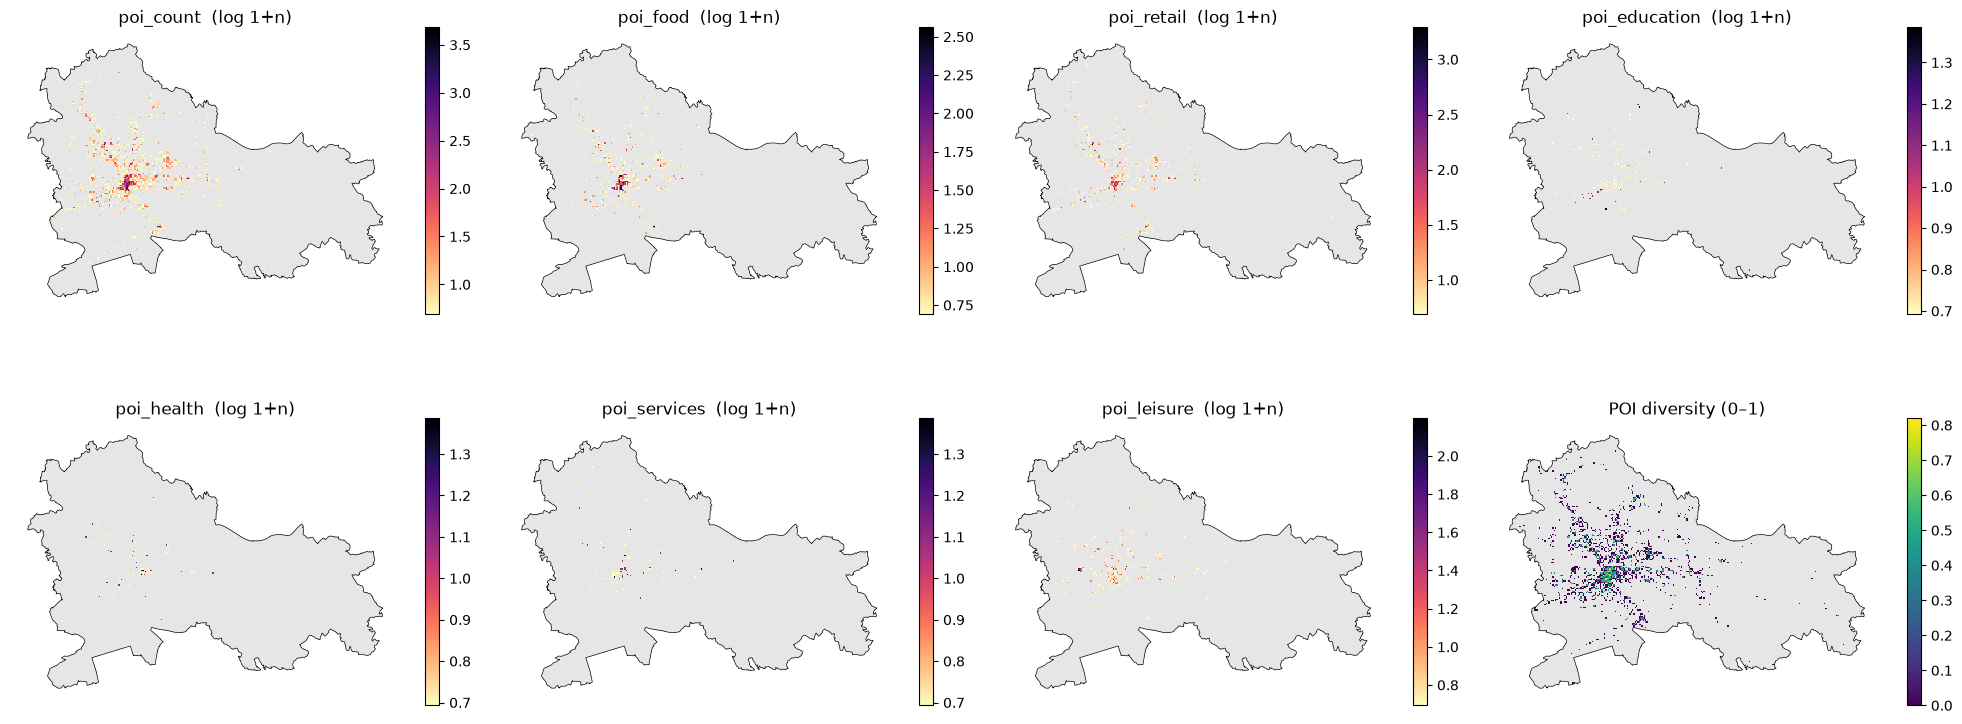

In [8]:
gdf = grid.merge(result.reset_index(), on="cell_id")

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, ["poi_count"] + [f"poi_{c}" for c in CATS] + ["poi_diversity"]):
    gdf.plot(ax=ax, color="#e6e6e6", linewidth=0)
    if col == "poi_diversity":
        gdf.dropna(subset=[col]).plot(ax=ax, column=col, cmap="viridis", linewidth=0, legend=True,
                                      legend_kwds={"shrink": 0.6})
        ax.set_title("POI diversity (0–1)")
    else:
        sub = gdf[gdf[col] > 0]
        sub.plot(ax=ax, column=np.log1p(sub[col]), cmap="magma_r", linewidth=0, legend=True,
                 legend_kwds={"shrink": 0.6})
        ax.set_title(f"{col}  (log 1+n)")
    mol.boundary.plot(ax=ax, color="black", linewidth=0.5)
    ax.set_axis_off()
plt.tight_layout()
fig.savefig(FIGURES / "04_poi.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Save

In [9]:
out = result.reset_index()
out.to_csv(PROCESSED / "ind_poi.csv", index=False)
print(f"Saved {len(out):,} rows to {PROCESSED / 'ind_poi.csv'}")

Saved 27,505 rows to C:\Users\Maks\Desktop\Maks_šola\FRI\masters\urban-analysis\data\processed\ind_poi.csv


## Summary
- 6 category counts, total count and diversity per cell, saved to `data/processed/ind_poi.csv`.

**Limitations to note in the thesis:**
- OSM completeness varies: the centre is mapped in more detail than the suburbs, so "no POI" can partly mean "not mapped".
- The Geofabrik free extract has **no offices** (`office=*`), so workplaces are under-represented in `poi_services`.
- A POI is one point regardless of size: a kiosk and a shopping centre both count as 1.
- The category list is our choice and must be described in the methods chapter.
- `poi_diversity` is NaN in cells without POI; decide before clustering (e.g. set to 0, or use it only together with `poi_count`).